# TotalEnergies | AI transformation portfolio charts

This notebook reads the saved and recalculated `portfolio_model_14_revised.xlsx` without modifying it. The 14 initiatives, their five-year financial cases, hurdles and weights are unchanged. All charts are generated with Matplotlib; PNG and SVG copies go to `work/projects/assets/`.

**Two different time frames:** Y0–Y5 is the financial valuation used in the project cases. The additional 15-year view is a separate, assumption-led illustration of discounted **net project value**, not a financial forecast, a replacement for the five-year NPV or an enterprise valuation. In particular, the H3 market, scaling costs and success probabilities are invented for scenario exploration and have not been validated. They must be changed or removed if unsupported. The course's approximate 10/20/70 distribution is a contextual reference, not a target or evidence for our projects.

Install requirements in your notebook environment: `pip install matplotlib openpyxl ipykernel`. Recalculate and save the workbook before running all cells; openpyxl reads cached results and cannot recalculate Excel formulas.

In [1]:
%matplotlib inline
from pathlib import Path
from collections import defaultdict
import csv, json, math
import openpyxl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

cwd = Path.cwd().resolve()
root = next((p for p in [cwd, *cwd.parents] if (p / 'work/finance/portfolio_model_14_revised.xlsx').exists()), None)
if root is None:
    raise FileNotFoundError('Run from the repository or one of its subdirectories')
model = root / 'work/finance/portfolio_model_14_revised.xlsx'
out = root / 'work/projects/assets'
out.mkdir(parents=True, exist_ok=True)
w = openpyxl.load_workbook(model, data_only=True)
inputs, metrics, calc, summary = [w[x] for x in ['Inputs','Metrics','Cash flow build','Portfolio']]

# Palette used in the project's previous TotalEnergies-inspired SVG artwork.
palette = {'H1':'#00509E', 'H2':'#F37021', 'H3':'#E30613', 'Enabler':'#3F2B86'}
scenario_colors = {'Downside':'#E30613', 'Base':'#00509E', 'Upside':'#84C225'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':17,
                     'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white',
                     'savefig.facecolor':'white','axes.axisbelow':True})
def export(fig, name):
    fig.savefig(out / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(out / f'{name}.svg', bbox_inches='tight')
    plt.show()

weights = [summary.cell(17,c).value for c in (2,3,4)]
assert all(isinstance(v,(float,int)) and v >= 0 for v in weights) and abs(sum(weights)-1) < 1e-9
records=[]
for n in range(14):
    r=n+2
    ident, label, horizon, hurdle, fx, cash_flag = [inputs.cell(r,c).value for c in range(1,7)]
    include=inputs.cell(r,21).value
    assert include in (0,1)
    investment=sum(inputs.cell(r,c).value for c in (7,8,9))*fx*include
    annual=inputs.cell(r,15).value*fx*cash_flag*include
    ramp=[inputs.cell(r,c).value for c in range(16,21)]
    flows, benefits, npvs = {}, {}, {}
    for j,name in enumerate(('Downside','Base','Upside')):
        row=2+(3*n+j)*7
        flows[name]=[calc.cell(row+5,2+t).value*include for t in range(6)]
        benefits[name]=[calc.cell(row+1,2+t).value*include for t in range(6)]
        npvs[name]=metrics.cell(2+3*n+j,5).value*include
    records.append(dict(id=ident,name=label,horizon=horizon,hurdle=hurdle,fx=fx,include=include,
                        investment=investment,annual=annual,ramp=ramp,flows=flows,benefits=benefits,npvs=npvs))
assert [r['id'] for r in records] == [f'P{x:02}' for x in range(1,14)]+['E01']
assert abs(sum(r['investment'] for r in records)-summary['B32'].value)<1e-8
assert abs(sum(sum(r['npvs'][name]*weights[j] for j,name in enumerate(('Downside','Base','Upside'))) for r in records)-summary['B18'].value)<1e-8
print('Loaded', len(records), 'initiatives; workbook NPV and initial investment reconcile.')

Loaded 14 initiatives; workbook NPV and initial investment reconcile.


## Editable long-term scenario assumptions

These parameters **do not change** the existing five-year Excel cases. They describe an optional commercial scale-up after Y5. P11's 2,000 MW × $15,000/MW/year is a hypothetical continuation beyond the 250 MW case, not evidence that this scale is available. P12's $12m/year is a purely illustrative future gross contribution: its scientific, commercial and IP viability have not been established. The market-entry years, scaling costs and probabilities are judgmental, not sourced forecasts.

The 15-year net-value illustration adds modelled incremental CAPEX, OPEX and a simplified 25% tax after Y5, then discounts each project's cash at its own hurdle. It is highly sensitive to the assumed H3 commercial success and costs and excludes working capital and terminal value. The Y0–Y5 portion uses the unchanged weighted Excel cases; H1/H2 and E01 then repeat their base Y5 net cash for ten years with no decay or replacement investment. Scale CAPEX is incurred only on the conditional continuation path, and loss carryforwards and tax depreciation on new CAPEX are ignored. These simplifications require review before an investment decision. All horizons receive the same Y0–Y15 window.

In [2]:
LONG_TERM = {
    'window_years': 15,
    # P11: unchanged Y1–Y5 financial model; possible 250 MW continuation in Y6–Y7,
    # then incremental commercial expansion. USD/MW/year margin is before project OPEX.
    'P11': {'maturity_year': 8, 'scale_mw': 2000, 'retained_usd_per_mw_year': 15000,
            'post_y5_success_probability': 0.60, 'expansion_year': 7,
            'expansion_capex_usdm': 4.0, 'annual_total_opex_usdm': 5.0},
    # P12: no benefit is modelled during Y1–Y5. Market potential is unknown.
    'P12': {'maturity_year': 10, 'conditional_annual_usdm': 12.0,
            'post_y5_success_probability': 0.30, 'expansion_year': 8,
            'expansion_capex_usdm': 6.0, 'annual_total_opex_usdm': 4.0},
    'h1_h2_post_y5_retention': 1.0,
    'enabler_post_y5_retention': 1.0,
    'post_y5_tax_rate': 0.25,
    # E01 is a cost-only enabler, shown at zero gross benefit.
    'enabler_activation_year': 1,
}
LONG_TERM['P11']['conditional_annual_usdm'] = (LONG_TERM['P11']['scale_mw'] * LONG_TERM['P11']['retained_usd_per_mw_year'] / 1e6)
assert LONG_TERM['window_years'] >= max(LONG_TERM['P11']['maturity_year'],LONG_TERM['P12']['maturity_year'])
for ident in ('P11','P12'):
    assert 0 <= LONG_TERM[ident]['post_y5_success_probability'] <= 1
    assert LONG_TERM[ident]['conditional_annual_usdm'] >= 0
    assert 6 <= LONG_TERM[ident]['expansion_year'] < LONG_TERM[ident]['maturity_year']
assert 0 <= LONG_TERM['post_y5_tax_rate'] <= 1
print(json.dumps(LONG_TERM,indent=2))

{
  "window_years": 15,
  "P11": {
    "maturity_year": 8,
    "scale_mw": 2000,
    "retained_usd_per_mw_year": 15000,
    "post_y5_success_probability": 0.6,
    "expansion_year": 7,
    "expansion_capex_usdm": 4.0,
    "annual_total_opex_usdm": 5.0,
    "conditional_annual_usdm": 30.0
  },
  "P12": {
    "maturity_year": 10,
    "conditional_annual_usdm": 12.0,
    "post_y5_success_probability": 0.3,
    "expansion_year": 8,
    "expansion_capex_usdm": 6.0,
    "annual_total_opex_usdm": 4.0
  },
  "h1_h2_post_y5_retention": 1.0,
  "enabler_post_y5_retention": 1.0,
  "post_y5_tax_rate": 0.25,
  "enabler_activation_year": 1
}


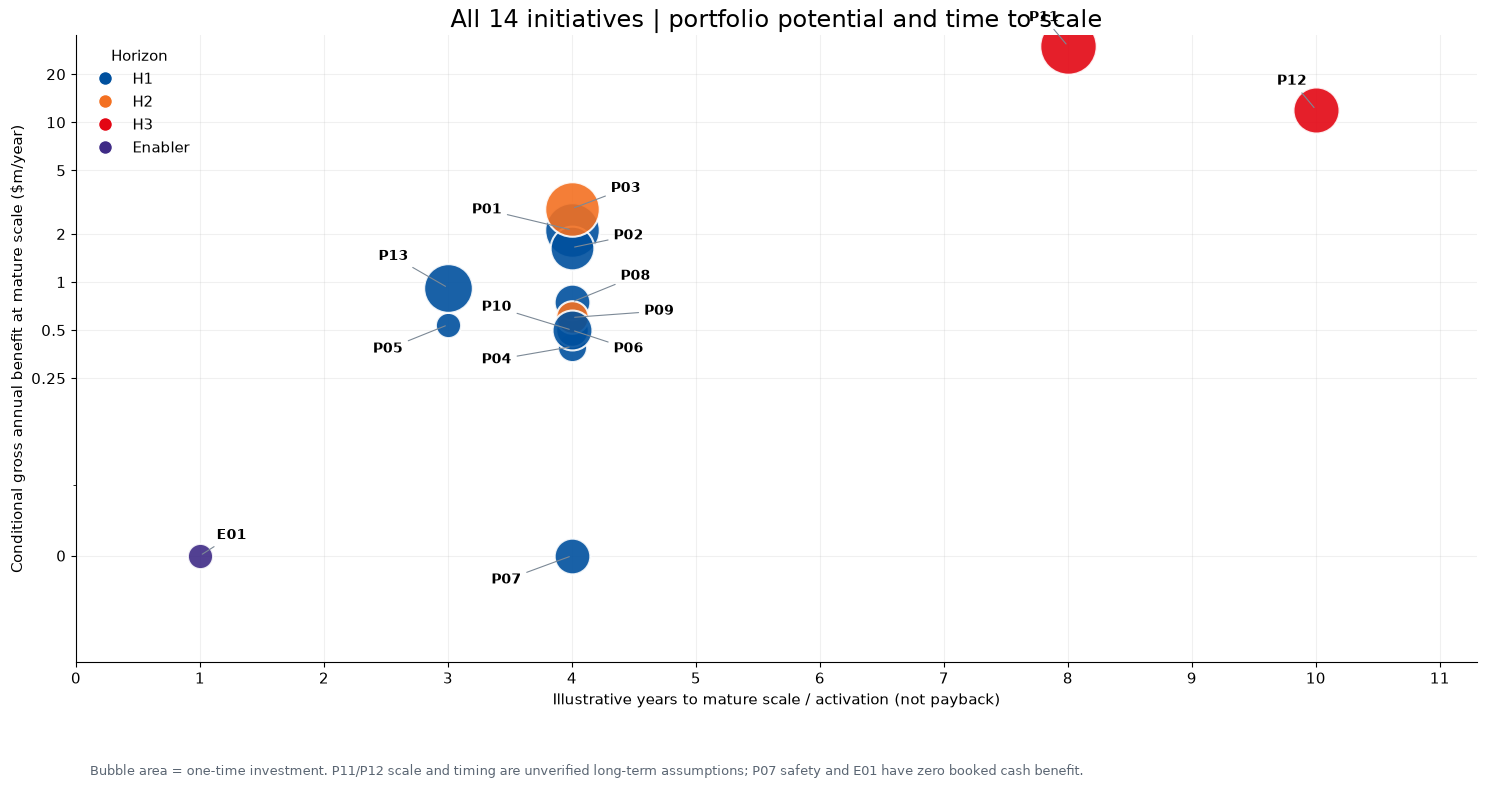

In [3]:
# Same chart for all 14 initiatives. Both axes are timing/value-at-scale concepts,
# never payback. H3 points are explicit long-term *conditional* hypotheses.
for r in records:
    ident=r['id']
    if ident in ('P11','P12'):
        r['maturity_year']=LONG_TERM[ident]['maturity_year']
        r['mature_gross']=LONG_TERM[ident]['conditional_annual_usdm']*r['include']
    elif ident == 'E01':
        r['maturity_year']=LONG_TERM['enabler_activation_year'];r['mature_gross']=0.0
    else:
        r['maturity_year']=next((y for y,x in enumerate(r['ramp'],1) if x>=1),5)
        r['mature_gross']=r['annual']

fig, ax=plt.subplots(figsize=(15,8))
offsets={'P01':(-72,12),'P02':(30,6),'P03':(28,12),'P04':(-65,-12),
         'P05':(-54,-20),'P06':(30,-16),'P07':(-58,-20),'P08':(35,16),
         'P09':(52,2),'P10':(-65,14),'P11':(-28,18),'P12':(-28,18),
         'P13':(-50,20),'E01':(12,12)}
for r in records:
    if not r['include']: continue
    x,y=r['maturity_year'],r['mature_gross']
    ax.scatter(x,y,s=max(40,r['investment']*1100),c=palette[r['horizon']],edgecolors='white',linewidths=1.5,alpha=.90,zorder=3)
    ax.annotate(r['id'],(x,y),xytext=offsets[r['id']],textcoords='offset points',fontweight='bold',fontsize=10,
                arrowprops={'arrowstyle':'-','color':'#7c8996','lw':.8},zorder=4)
ax.set_yscale('symlog',linthresh=.25)
ax.set(xlim=(0,11.3),ylim=(-.15,35),xticks=range(0,12),yticks=[0,.25,.5,1,2,5,10,20],
       xlabel='Illustrative years to mature scale / activation (not payback)',
       ylabel='Conditional gross annual benefit at mature scale ($m/year)',
       title='All 14 initiatives | portfolio potential and time to scale')
ax.set_yticklabels(['0','0.25','0.5','1','2','5','10','20'])
ax.grid(alpha=.18)
handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=palette[h],markersize=10,label=h) for h in palette]
ax.legend(handles=handles,title='Horizon',loc='upper left',frameon=False)
ax.text(.01,-.18,'Bubble area = one-time investment. P11/P12 scale and timing are unverified long-term assumptions; '
        'P07 safety and E01 have zero booked cash benefit.',transform=ax.transAxes,fontsize=9,color='#5B6673')
fig.tight_layout();export(fig,'notebook_portfolio_bubble')

## Three mixes: initial capital, five-year benefits, 15-year potential

The first two bars are calculated from the unchanged workbook. The last bar is a **separate 15-year net-value illustration**: it adds probability-adjusted post-Y5 cash flows to the weighted Y0–Y5 project NPVs, using each project's hurdle. H3 leads under the explicitly assumed scale, timing, costs and probabilities; this is not evidence that it will do so. E01 has a negative cost contribution and appears separately rather than being silently converted to a positive share.

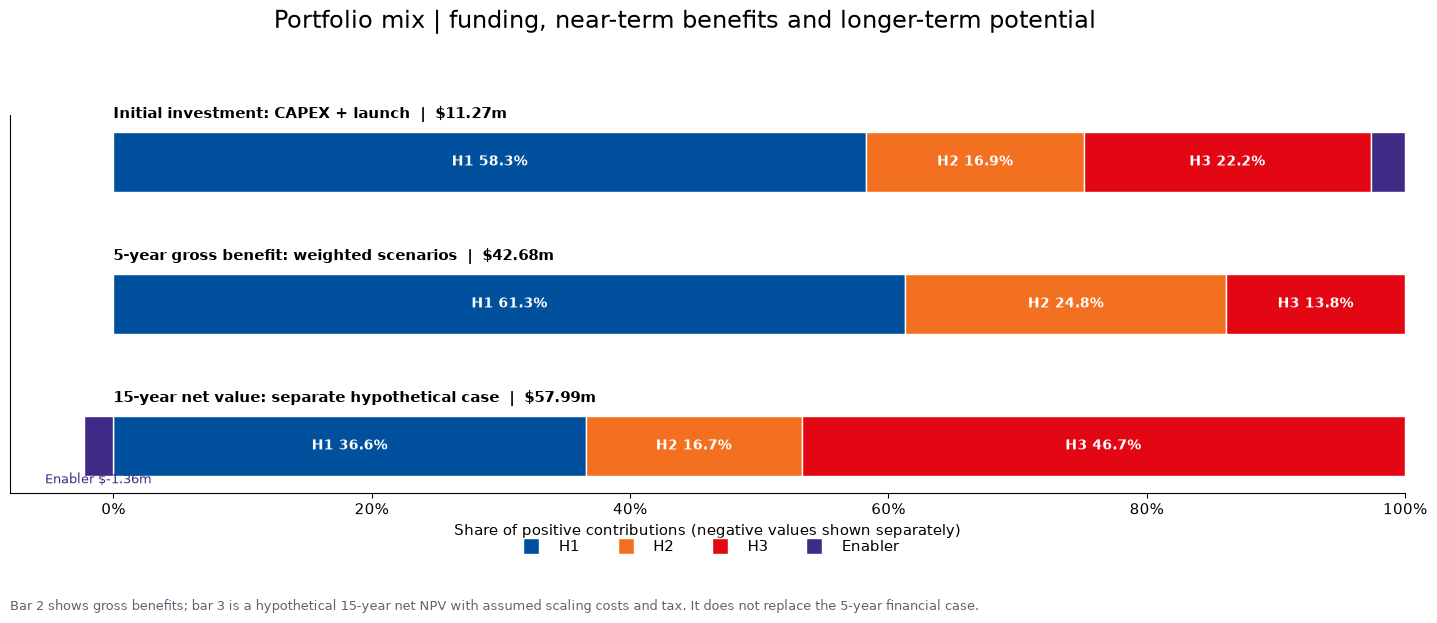

15-year net NPV illustration by horizon, $m: {'H1': 21.720967559805388, 'H2': 9.903019009320221, 'H3': 27.726780182525907, 'Enabler': -1.363953057366261}
H3 share of positive illustrative 15-year NPV: 46.7%


In [4]:
mix_cap=defaultdict(float); mix_5=defaultdict(float);mix_15=defaultdict(float);mix_net15=defaultdict(float)
long_term_by_project={}; long_term_net_cash={}; long_term_npv_by_project={}
for r in records:
    h=r['horizon'];mix_cap[h]+=r['investment']
    mix_5[h]+=sum(weights[j]*sum(r['benefits'][s][1:]) for j,s in enumerate(('Downside','Base','Upside')))
    projection=list(r['benefits']['Base'][1:])
    if r['id']=='P11':
        p=LONG_TERM['P11']['post_y5_success_probability']
        for year in range(6,LONG_TERM['window_years']+1):
            gross=r['annual'] if year<LONG_TERM['P11']['maturity_year'] else r['mature_gross']
            projection.append(p*gross)
    elif r['id']=='P12':
        p=LONG_TERM['P12']['post_y5_success_probability']
        for year in range(6,LONG_TERM['window_years']+1):
            projection.append(p*r['mature_gross'] if year>=LONG_TERM['P12']['maturity_year'] else 0)
    elif h in ('H1','H2'):
        projection.extend([r['annual']*LONG_TERM['h1_h2_post_y5_retention']]*(LONG_TERM['window_years']-5))
    else:
        projection.extend([0]*(LONG_TERM['window_years']-5))
    assert len(projection)==LONG_TERM['window_years']
    long_term_by_project[r['id']]=projection
    mix_15[h]+=sum(projection)
    weighted_npv_5=sum(weights[j]*r['npvs'][s] for j,s in enumerate(('Downside','Base','Upside')))
    future=[]
    for year in range(6,LONG_TERM['window_years']+1):
        if r['id']=='P11':
            p=LONG_TERM['P11']['post_y5_success_probability']
            if year<LONG_TERM['P11']['maturity_year']:
                cf=p*r['flows']['Base'][5]
            else:
                profit=r['mature_gross']-LONG_TERM['P11']['annual_total_opex_usdm']
                cf=p*(profit-max(0,profit)*LONG_TERM['post_y5_tax_rate'])
            if year==LONG_TERM['P11']['expansion_year']: cf-=p*LONG_TERM['P11']['expansion_capex_usdm']
        elif r['id']=='P12':
            p=LONG_TERM['P12']['post_y5_success_probability']
            profit=r['mature_gross']-LONG_TERM['P12']['annual_total_opex_usdm']
            cf=p*(profit-max(0,profit)*LONG_TERM['post_y5_tax_rate']) if year>=LONG_TERM['P12']['maturity_year'] else 0
            if year==LONG_TERM['P12']['expansion_year']: cf-=p*LONG_TERM['P12']['expansion_capex_usdm']
        else:
            continuation=(LONG_TERM['enabler_post_y5_retention'] if h=='Enabler' else LONG_TERM['h1_h2_post_y5_retention'])
            cf=r['flows']['Base'][5]*continuation
        future.append(cf*r['include'])
    long_term_net_cash[r['id']]=future
    value=weighted_npv_5+sum(cf/(1+r['hurdle'])**year for year,cf in enumerate(future,6))
    long_term_npv_by_project[r['id']]=value
    mix_net15[h]+=value

groups=('H1','H2','H3','Enabler')
bars=[('Initial investment: CAPEX + launch',mix_cap),
      ('5-year gross benefit: weighted scenarios',mix_5),
      ('15-year net value: separate hypothetical case',mix_net15)]
fig,ax=plt.subplots(figsize=(15,7));ax.set_xlim(-8,100)
for y,(label,data) in enumerate(bars):
    total=sum(data.values());positive=sum(v for v in data.values() if v>0);assert positive>0
    left=0
    for h in groups:
        share=100*max(data[h],0)/positive
        if share>0:
            ax.barh(y,share,left=left,color=palette[h],edgecolor='white',height=.42)
            if share>=5: ax.text(left+share/2,y,f'{h} {share:.1f}%',ha='center',va='center',fontweight='bold',color='white',fontsize=10)
        left+=share
    for h in groups:
        if data[h]<0:
            share=100*data[h]/positive
            ax.barh(y,share,left=0,color=palette[h],edgecolor='white',height=.42)
            ax.annotate(f'{h} ${data[h]:+.2f}m',xy=(share/2,y),xytext=(0,-27),textcoords='offset points',ha='center',fontsize=9,color=palette[h])
    ax.text(0,y-.28,f'{label}  |  ${total:,.2f}m',fontweight='bold',va='bottom')
ax.set(yticks=[],xlabel='Share of positive contributions (negative values shown separately)')
fig.suptitle('Portfolio mix | funding, near-term benefits and longer-term potential',fontsize=17,y=.99)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100));ax.invert_yaxis()
ax.legend(handles=[Line2D([0],[0],marker='s',color='w',markerfacecolor=palette[h],markersize=11,label=h) for h in groups],
          ncol=4,loc='lower center',bbox_to_anchor=(.5,-.20),frameon=False)
ax.text(0,-.31,'Bar 2 shows gross benefits; bar 3 is a hypothetical 15-year net NPV with assumed scaling costs and tax. '
        'It does not replace the 5-year financial case.',
        transform=ax.transAxes,fontsize=9,color='#5B6673')
fig.subplots_adjust(top=.84,bottom=.30,left=.05,right=.98);export(fig,'notebook_portfolio_mix')
print('15-year net NPV illustration by horizon, $m:',dict(mix_net15))
print('H3 share of positive illustrative 15-year NPV:',f"{mix_net15['H3']/sum(max(x,0) for x in mix_net15.values()):.1%}")

## Four focus J-curves and complete portfolio

The curves use unchanged five-year **net** cash flows from Excel, without discounting, not the separate 15-year assumptions. P13 is shown in EUR; all other figures and the portfolio are in USD.

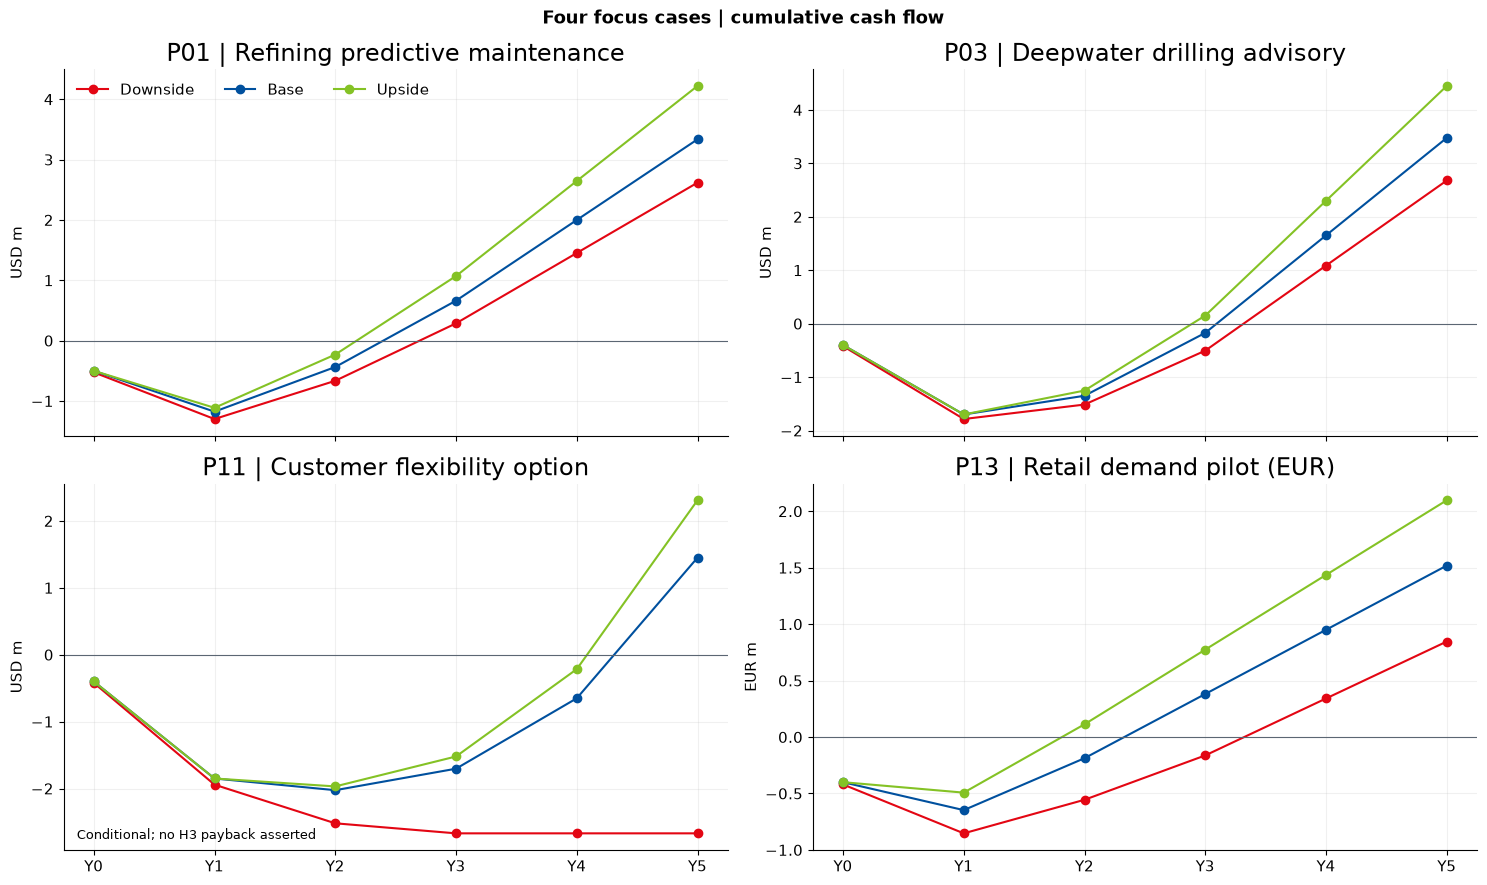

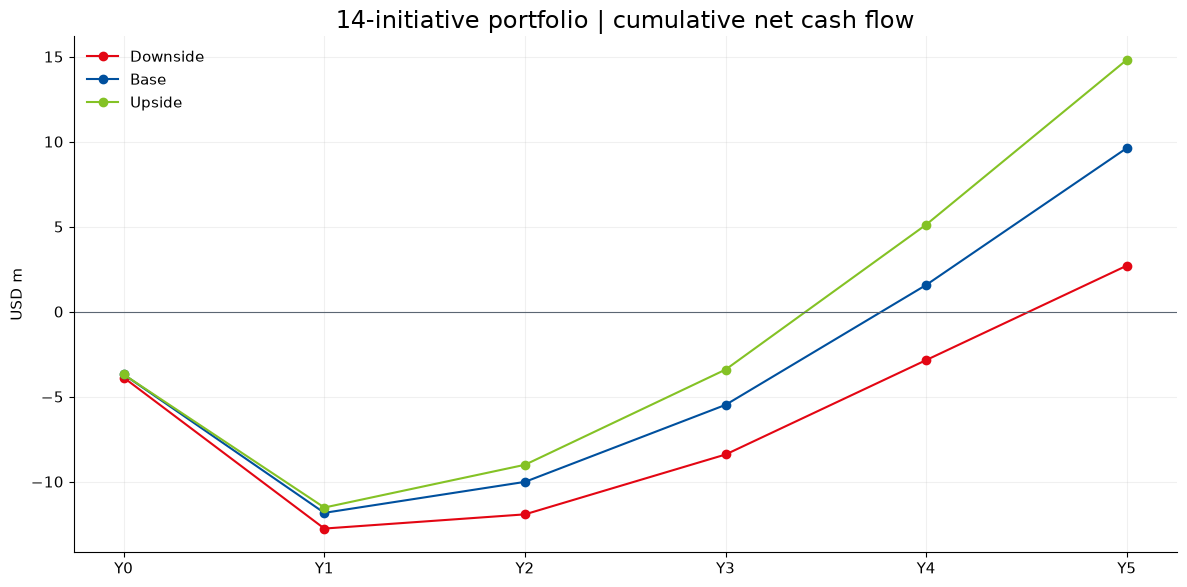

In [5]:
fig, axes=plt.subplots(2,2,figsize=(15,9),sharex=True)
for ax,ident in zip(axes.flat,('P01','P03','P11','P13')):
    r=next(x for x in records if x['id']==ident); fx=r['fx'] if ident=='P13' else 1
    for s in ('Downside','Base','Upside'):
        values=[];running=0
        for cf in r['flows'][s]: running+=cf/fx;values.append(running)
        ax.plot(range(6),values,marker='o',label=s,color=scenario_colors[s])
    ax.axhline(0,color='#5B6673',lw=.8);ax.grid(alpha=.18)
    ax.set_title(f"{ident} | {r['name']}");ax.set_ylabel('EUR m' if ident=='P13' else 'USD m');ax.set_xticks(range(6),[f'Y{x}' for x in range(6)])
    if ident=='P11': ax.text(.02,.03,'Conditional; no H3 payback asserted',transform=ax.transAxes,fontsize=9)
axes[0,0].legend(frameon=False,ncol=3);fig.suptitle('Four focus cases | cumulative cash flow',fontweight='bold');fig.tight_layout();export(fig,'notebook_focus_jcurves')

for ident in ('P01','P03','P11','P13'):
    r=next(x for x in records if x['id']==ident);fx=r['fx'] if ident=='P13' else 1
    fig,ax=plt.subplots(figsize=(10,5))
    for s in ('Downside','Base','Upside'):
        values=[];running=0
        for cf in r['flows'][s]:running+=cf/fx;values.append(running)
        ax.plot(range(6),values,marker='o',label=s,color=scenario_colors[s])
    ax.axhline(0,color='#5B6673',lw=.8);ax.grid(alpha=.18);ax.legend(frameon=False)
    ax.set(xticks=range(6),xticklabels=[f'Y{x}' for x in range(6)],ylabel='EUR m' if ident=='P13' else 'USD m',title=f"{ident} | {r['name']}")
    if ident=='P11':ax.text(.02,.03,'Conditional; no H3 payback asserted',transform=ax.transAxes,fontsize=9)
    fig.tight_layout();fig.savefig(out/f'notebook_{ident.lower()}_jcurve.png',dpi=180,bbox_inches='tight')
    fig.savefig(out/f'notebook_{ident.lower()}_jcurve.svg',bbox_inches='tight');plt.close(fig)

fig,ax=plt.subplots(figsize=(12,6))
for j,s in enumerate(('Downside','Base','Upside')):
    vals=[summary.cell(6+y,2+j).value for y in range(6)]
    ax.plot(range(6),vals,marker='o',color=scenario_colors[s],label=s)
ax.axhline(0,color='#5B6673',lw=.8);ax.grid(alpha=.18);ax.legend(frameon=False)
ax.set(xticks=range(6),xticklabels=[f'Y{x}' for x in range(6)],ylabel='USD m',title='14-initiative portfolio | cumulative net cash flow')
fig.tight_layout();export(fig,'notebook_portfolio_jcurve')

## Reconciliation and net value

The weighted net-value chart retains negative H3 and enabler contributions in the five-year model. It is distinct from gross benefits and the 15-year potential.

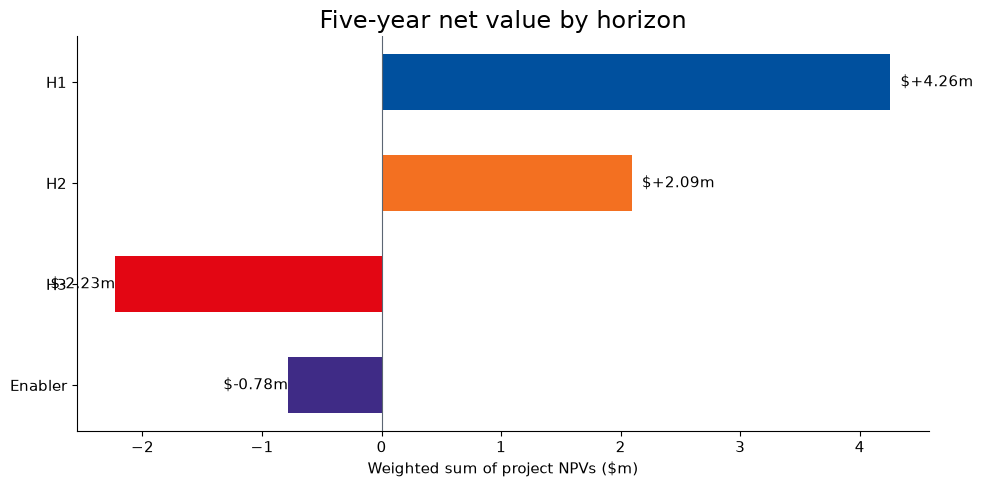

Five-year weighted net NPV: 3.3451 USD m


In [6]:
net=defaultdict(float)
for r in records:
    net[r['horizon']]+=sum(weights[j]*r['npvs'][s] for j,s in enumerate(('Downside','Base','Upside')))
assert abs(sum(net.values())-summary['B18'].value)<1e-8
fig,ax=plt.subplots(figsize=(10,5))
for i,h in enumerate(groups):
    ax.barh(i,net[h],color=palette[h],height=.55);ax.text(net[h],i,f'  ${net[h]:+.2f}m',va='center',ha='left' if net[h]>=0 else 'right')
ax.axvline(0,color='#5B6673',lw=.8);ax.set(yticks=range(4),yticklabels=groups,xlabel='Weighted sum of project NPVs ($m)',title='Five-year net value by horizon');ax.invert_yaxis()
fig.tight_layout();export(fig,'notebook_net_contributions')
result={'weights':weights,'capital':dict(mix_cap),'gross_5y':dict(mix_5),
        'gross_15y_illustrative':dict(mix_15),'net_5y_weighted_npv':dict(net),'net_15y_illustrative':dict(mix_net15),
        'long_term_assumptions':LONG_TERM,'long_term_gross_benefits_by_project_and_year':long_term_by_project,
        'long_term_net_cash_y6_y15':long_term_net_cash,'long_term_npv_by_project':long_term_npv_by_project,
        'project_plot_inputs':[{k:r[k] for k in ('id','horizon','investment','maturity_year','mature_gross')} for r in records]}
(out/'notebook_chart_data.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
with (out/'notebook_longterm_cashflows.csv').open('w',newline='',encoding='utf-8-sig') as f:
    writer=csv.writer(f)
    writer.writerow(['Project','Horizon','Hurdle','Weighted NPV Y0–Y5',*[f'Expected net cash Y{y}' for y in range(6,LONG_TERM['window_years']+1)],'15-year illustrative NPV'])
    for r in records:
        initial=sum(weights[j]*r['npvs'][s] for j,s in enumerate(('Downside','Base','Upside')))
        writer.writerow([r['id'],r['horizon'],r['hurdle'],initial,*long_term_net_cash[r['id']],long_term_npv_by_project[r['id']]])
print('Five-year weighted net NPV:',round(sum(net.values()),4),'USD m')